<a href="https://colab.research.google.com/github/dramaticforyouenjoy-sudo/RIT-Trading-Competition-2026/blob/main/Performance_Returns_For_SMA_Cross.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_1549/3321246918.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("NVDA",start="2025-01-01",end="2026-11-8",progress=False,multi_level_index=False)


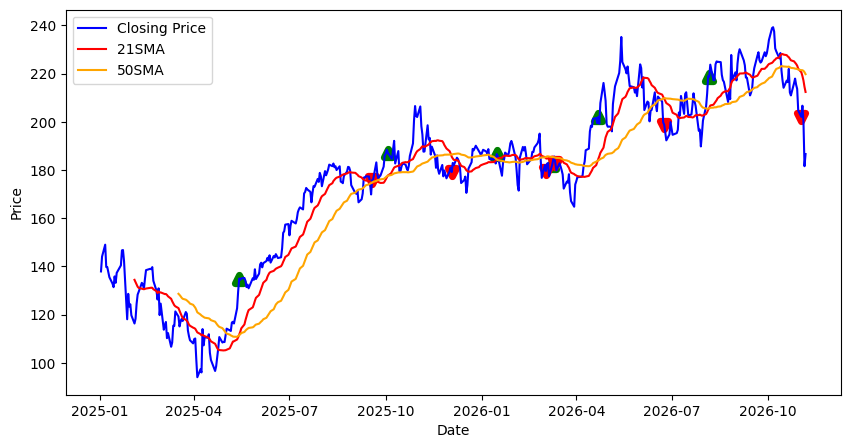

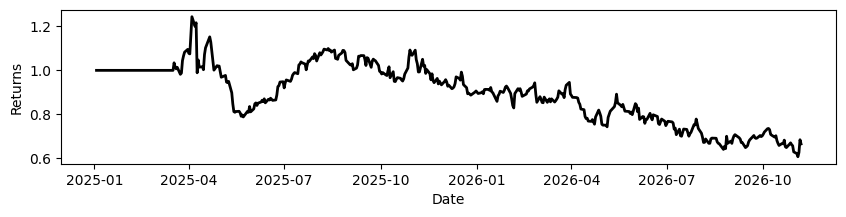

                 Close        High         Low        Open     Volume  \
Date                                                                    
2026-01-23  187.231873  189.157375  186.383866  187.062271  142748100   
2026-01-26  186.034683  188.678491  185.555808  186.723075  124799600   
2026-01-27  188.079895  189.556436  185.266471  186.802884  143711600   
2026-01-28  191.072891  191.900955  189.396805  190.823475  148552700   
2026-01-29  192.060562  193.028299  185.625623  190.893295  171764400   
...                ...         ...         ...         ...        ...   
2026-11-02  202.059998  209.979996  201.660004  207.529999  119272200   
2026-11-03  206.690002  209.139999  205.929993  207.960007   91943400   
2026-11-04  200.130005  206.789993  199.679993  203.500000  149033300   
2026-11-05  181.600006  196.250000  181.460007  196.070007  306127800   
2026-11-06  186.639999  194.899994  185.220001  191.100006  179722400   

                 21SMA       50SMA  signal   retur

In [2]:
from matplotlib.typing import MarkerType
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
!pip install pandas_ta_classic -q
import pandas_ta_classic as ta

df = yf.download("NVDA",start="2025-01-01",end="2026-11-8",progress=False,multi_level_index=False)

df['21SMA'] = df.ta.sma(length=21,append=False)
df['50SMA'] = df.ta.sma(length=50,append=False)

df['signal'] = 0

df.loc[df['21SMA'] > df['50SMA'], 'signal'] = 1
df.loc[df['21SMA'] < df['50SMA'], 'signal'] = -1

buy_points = df[df['signal'].diff() == 2]
sell_points = df[df['signal'].diff() == -2]

df['returns'] = df['Close'].pct_change()
df['strategy_returns'] = df['signal'].shift(1)*df['returns']

df['cumulative_returns'] = (1 + df['returns']).cumprod()
df['cumulative_strategy_returns'] = (1+df['strategy_returns']).cumprod()

plt.figure(figsize=(10,5))
plt.plot(df.index,df['Close'],label='Closing Price',color='blue')
plt.plot(df.index,df['21SMA'],label='21SMA',color='red')
plt.plot(df.index,df['50SMA'],label='50SMA',color='orange')
plt.scatter(buy_points.index,buy_points['Close'],marker='^',color='green',linewidths=5)
plt.scatter(sell_points.index,sell_points['Close'],marker='v',color='red',linewidths=5)

plt.xlabel('Date', fontsize=10)
plt.ylabel('Price',fontsize=10)
plt.legend()
plt.show()

plt.figure(figsize=(10,2))
plt.plot(df.index,df['cumulative_strategy_returns'],label='cumulative returns',color='black',linewidth=2)
plt.xlabel('Date',fontsize=10)
plt.ylabel('Returns',fontsize=10)
plt.show()

print(df.tail(200))
